<a href="https://colab.research.google.com/github/julianovale/PO1/blob/main/PO1_003_Problema_Fluxo_Redes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install ortools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.8/29.8 MB 71.8 MB/s  0:00:00


# Problema do Fluxo Máximo (Rede Ferroviária)

Suponha uma rede ferroviária composta por **5 estações** (nós) conectadas por trechos direcionados (arestas), na qual cada conexão possui uma capacidade máxima de transporte.

O objetivo é determinar a **maior quantidade possível de produto** que pode ser transportada da **estação de origem (Nó 1)** até a **estação de destino (Nó 5)**, respeitando os limites de capacidade de cada trecho e garantindo que todo o volume que entra em uma estação intermediária saia dela (conservação de fluxo).

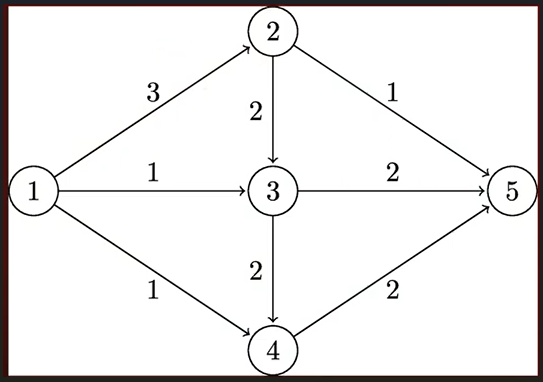![Grafo do Problema do Fluxo Máximo](grafo_fluxo_maximo.png)

## Tabela de Conexões e Capacidades

| Trecho (Origem → Destino) | Variável | Capacidade Máxima ($K_{i,j}$) |
| :--- | :--- | :--- |
| **Estação 1 → Estação 2** | $x_{1,2}$ | 3 |
| **Estação 1 → Estação 3** | $x_{1,3}$ | 1 |
| **Estação 1 → Estação 4** | $x_{1,4}$ | 1 |
| **Estação 2 → Estação 3** | $x_{2,3}$ | 2 |
| **Estação 2 → Estação 5** | $x_{2,5}$ | 1 |
| **Estação 3 → Estação 4** | $x_{3,4}$ | 2 |
| **Estação 3 → Estação 5** | $x_{3,5}$ | 2 |
| **Estação 4 → Estação 5** | $x_{4,5}$ | 2|

## Modelo Matemático

**Variáveis de Decisão:**
Cada variável $x_{i,j}$ representa a quantidade transportada da estação $i$ até a estação $j$ (arestas inexistentes são omitidas do modelo):
* $x_{1,2}, \; x_{1,3}, \; x_{1,4}, \; x_{2,3}, \; x_{2,5}, \; x_{3,4}, \; x_{3,5}, \; x_{4,5}$

**Função Objetivo (Maximizar o fluxo que sai da origem — Nó 1):**
$$\max Z = x_{1,2} + x_{1,3} + x_{1,4}$$

**Restrições de Conservação de Fluxo (Nós intermediários 2, 3 e 4):**
* **Nó 2:** $x_{1,2} - x_{2,3} - x_{2,5} = 0$
* **Nó 3:** $x_{1,3} + x_{2,3} - x_{3,4} - x_{3,5} = 0$
* **Nó 4:** $x_{1,4} + x_{3,4} - x_{4,5} = 0$

**Restrições de Capacidade das Arestas:**
* $x_{1,2} \le 3$
* $x_{1,3} \le 1$
* $x_{1,4} \le 1$
* $x_{2,3} \le 2$
* $x_{2,5} \le 1$
* $x_{3,4} \le 2$
* $x_{3,5} \le 2$
* $x_{4,5} \le 2$

**Restrições de Não Negatividade (grafo direcionado):**
* $x_{1,2}, \; x_{1,3}, \; x_{1,4}, \; x_{2,3}, \; x_{2,5}, \; x_{3,4}, \; x_{3,5}, \; x_{4,5} \ge 0$

In [2]:
from ortools.linear_solver import pywraplp

def resolver_fluxo_maximo():
    # Instancia o solver GLOP (específico para Programação Linear)
    solver = pywraplp.Solver.CreateSolver('GLOP')
    if not solver:
        print("Solver não encontrado.")
        return

    # 1. Variáveis de Decisão (não-negativas: x_ij >= 0)
    x12 = solver.NumVar(0, solver.infinity(), 'x_1_2')
    x13 = solver.NumVar(0, solver.infinity(), 'x_1_3')
    x14 = solver.NumVar(0, solver.infinity(), 'x_1_4')
    x23 = solver.NumVar(0, solver.infinity(), 'x_2_3')
    x25 = solver.NumVar(0, solver.infinity(), 'x_2_5')
    x34 = solver.NumVar(0, solver.infinity(), 'x_3_4')
    x35 = solver.NumVar(0, solver.infinity(), 'x_3_5')
    x45 = solver.NumVar(0, solver.infinity(), 'x_4_5')

    # 2. Restrições de Conservação de Fluxo (Nós intermediários 2, 3 e 4)
    solver.Add(x12 - x23 - x25 == 0, 'Conservacao_No_2')
    solver.Add(x13 + x23 - x34 - x35 == 0, 'Conservacao_No_3')
    solver.Add(x14 + x34 - x45 == 0, 'Conservacao_No_4')

    # 3. Restrições de Capacidade das Arestas
    solver.Add(x12 <= 3, 'Cap_1_2')
    solver.Add(x13 <= 1, 'Cap_1_3')
    solver.Add(x14 <= 1, 'Cap_1_4')
    solver.Add(x23 <= 2, 'Cap_2_3')
    solver.Add(x25 <= 1, 'Cap_2_5')
    solver.Add(x34 <= 2, 'Cap_3_4')
    solver.Add(x35 <= 2, 'Cap_3_5')
    solver.Add(x45 <= 2, 'Cap_4_5')

    # 4. Função Objetivo: Maximizar o fluxo que sai da origem (Nó 1)
    solver.Maximize(x12 + x13 + x14)

    # 5. Resolve o problema
    status = solver.Solve()

    # 6. Exibe os resultados
    if status == pywraplp.Solver.OPTIMAL:
        print('Solução Ótima Encontrada!')
        print(f'Fluxo Máximo (Origem 1 -> Destino 5): {solver.Objective().Value():.0f} unidades\n')

        arestas = [
            (x12, 3), (x13, 1), (x14, 1),
            (x23, 2), (x25, 1), (x34, 2),
            (x35, 2), (x45, 2)
        ]

        print('Fluxo por trecho (Utilizado / Capacidade):')
        for var, cap in arestas:
            print(f'- {var.name()}: {var.solution_value():.0f} / {cap}')

        chegada_destino = x25.solution_value() + x35.solution_value() + x45.solution_value()
        print(f'\nTotal que chega ao destino (Nó 5): {chegada_destino:.0f} unidades')
    else:
        print('O problema não possui uma solução ótima viável.')

# Executa a função
resolver_fluxo_maximo()

Solução Ótima Encontrada!
Fluxo Máximo (Origem 1 -> Destino 5): 5 unidades

Fluxo por trecho (Utilizado / Capacidade):
- x_1_2: 3 / 3
- x_1_3: 1 / 1
- x_1_4: 1 / 1
- x_2_3: 2 / 2
- x_2_5: 1 / 1
- x_3_4: 1 / 2
- x_3_5: 2 / 2
- x_4_5: 2 / 2

Total que chega ao destino (Nó 5): 5 unidades
